# Slovak AI Olympiad — Task 2: MNIST Digit Inpainting & Elastic Corruption Restoration
**Author:** Kristian Hudák  
**Competition:** National Olympiad in Artificial Intelligence (OAI) — Home Qualifier Round

### Problem Description & Architectural Solution

The challenge required repairing a dataset of 2,000 handwritten MNIST digits that had been severely corrupted by synthetic erasure lines modeled as cubic Bézier curves (rubbering/elastic deformation).

**Methodology:**
1. **Baseline Pretrained Autoencoder:** Loaded a standard Convolutional Autoencoder pretrained on clean MNIST digits.
2. **Specialized Fine-Tuning (`RepairDataset`):** Fine-tuned the encoder-decoder network on 2,000 pairs of dynamically corrupted digits alongside their original clean ground truth.
3. **Inpainting & Artifact Removal:** The convolutional layers learn to suppress the sharp high-frequency edge artifacts introduced by the eraser curves while smoothly reconstructing missing stroke topologies from surrounding contextual features.
4. **Reconstruction & Export:** The fine-tuned network (`repairer.pth`) was used to reconstruct the competition evaluation set, producing the restored tensor dataset `2000_fixed_digits.pt` while strictly preserving original handwriting styles and digit ordering.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import Dataset, DataLoader
import random
import cv2
from ipywidgets import interact, IntSlider
from IPython.display import display, clear_output


In [2]:
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
print(device)


cuda:0


In [3]:
# Cubic Bézier curve generation for synthetic elastic rubbering/erasure corruption
def bezier_curve(P0, P1, P2, P3, t):
    return ((1 - t)**3) * P0 + 3 * (1 - t)**2 * t * P1 + 3 * (1 - t) * (t**2) * P2 + (t**3) * P3

def rubber(img, rubber_thickness=1.2):
    img = img.clone()
    _, H, W = img.shape

    # random control points within the image
    P0 = np.array([np.random.uniform(0, H), np.random.uniform(0, W)])
    P1 = np.array([np.random.uniform(0, H), np.random.uniform(0, W)])
    P2 = np.array([np.random.uniform(0, H), np.random.uniform(0, W)])
    P3 = np.array([np.random.uniform(0, H), np.random.uniform(0, W)])

    # sample the spline
    t = np.linspace(0, 1, 300)
    curve = np.array([bezier_curve(P0, P1, P2, P3, ti) for ti in t])

    # compute minimum distance from each pixel to the curve
    curve_tensor = torch.tensor(curve, dtype=torch.float32)  # shape [300, 2]
    Y, X = torch.meshgrid(
        torch.arange(H, dtype=torch.float32),
        torch.arange(W, dtype=torch.float32),
        indexing="ij"
    )
    distances = torch.cdist(torch.stack([Y.flatten(), X.flatten()], dim=1), curve_tensor).min(dim=1).values.reshape(H, W)

    # apply erasing
    mask = distances < rubber_thickness
    img[0][mask] = 0.0

    return img


In [4]:
class UnlabeledTensorDataset(Dataset):
    def __init__(self, tensor):
        self.tensor = tensor

    def __len__(self):
        return len(self.tensor)

    def __getitem__(self, idx):
        return self.tensor[idx], self.tensor[idx]


In [5]:
# Ingest 2,000 corrupted digit tensors
!wget http://agentspace.org/download/2000_rubbered_digits.pt


--2026-01-13 15:46:00--  http://agentspace.org/download/2000_rubbered_digits.pt
Resolving agentspace.org (agentspace.org)... 62.168.101.9
Connecting to agentspace.org (agentspace.org)|62.168.101.9|:80... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://www.agentspace.org/download/2000_rubbered_digits.pt [following]
--2026-01-13 15:46:01--  https://www.agentspace.org/download/2000_rubbered_digits.pt
Resolving www.agentspace.org (www.agentspace.org)... 62.168.101.9
Connecting to www.agentspace.org (www.agentspace.org)|62.168.101.9|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 6273668 (6.0M) [application/vnd.snesdev-page-table]
Saving to: ‘2000_rubbered_digits.pt’

2000_rubbered_digit 100%[===================>]   5.98M   602KB/s    in 14s     

2026-01-13 15:46:18 (424 KB/s) - ‘2000_rubbered_digits.pt’ saved [6273668/6273668]



In [6]:
loaded_images = torch.load("2000_rubbered_digits.pt")
new_dataset = UnlabeledTensorDataset(loaded_images)

print(len(new_dataset))      # 2000
print(new_dataset[0][0].shape)  # torch.Size([1, 28, 28])


2000
torch.Size([1, 28, 28])


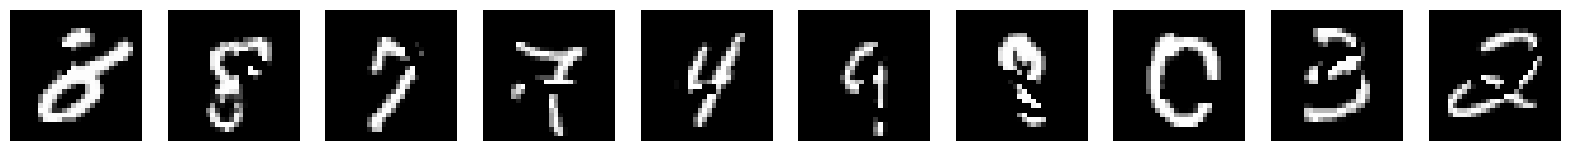

In [7]:
# Preview corrupted digit samples
plt.figure(figsize=(20, 2))
for i in range(10):
    img = (new_dataset[i][0].squeeze(0).detach().numpy()*255).astype(np.uint8)
    plt.subplot(1, 10, i+1)
    plt.imshow(img, cmap='gray')
    plt.axis('off')
plt.show()


In [8]:
# Convolutional Autoencoder architecture
class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 8, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(8, 8, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8, 8, kernel_size=3),
            nn.ReLU(),
            nn.Conv2d(8, 8, kernel_size=3),
            nn.Sigmoid(),
            nn.Flatten()
        )
        self.decoder = nn.Sequential(
            nn.Unflatten(1, (8, 3, 3)),
            nn.ConvTranspose2d(8, 8, kernel_size=3),
            nn.ReLU(),
            nn.ConvTranspose2d(8, 8, kernel_size=3),
            nn.ReLU(),
            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv2d(8, 8, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv2d(16, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 1, kernel_size=3, padding=1),
            nn.Sigmoid()
        )
    def forward(self, x):
        # apply encoder
        features = self.encoder(x)
        # apply decoder
        return self.decoder(features)
    def __str__(self):
        return str(self.encoder)+str(self.decoder)


In [9]:
autoencoder = Autoencoder()


In [10]:
!wget http://agentspace.org/download/pytorch_mnist_autoencoder_model.pth
model_name = 'pytorch_mnist_autoencoder_model.pth'


--2026-01-13 15:46:19--  http://agentspace.org/download/pytorch_mnist_autoencoder_model.pth
Resolving agentspace.org (agentspace.org)... 62.168.101.9
Connecting to agentspace.org (agentspace.org)|62.168.101.9|:80... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://www.agentspace.org/download/pytorch_mnist_autoencoder_model.pth [following]
--2026-01-13 15:46:19--  https://www.agentspace.org/download/pytorch_mnist_autoencoder_model.pth
Resolving www.agentspace.org (www.agentspace.org)... 62.168.101.9
Connecting to www.agentspace.org (www.agentspace.org)|62.168.101.9|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 52651 (51K)
Saving to: ‘pytorch_mnist_autoencoder_model.pth’

pytorch_mnist_autoe 100%[===================>]  51.42K  76.6KB/s    in 0.7s    

2026-01-13 15:46:21 (76.6 KB/s) - ‘pytorch_mnist_autoencoder_model.pth’ saved [52651/52651]



In [11]:
autoencoder = Autoencoder()


In [12]:
autoencoder.load_state_dict(torch.load(model_name))


<All keys matched successfully>

In [13]:
decoder = autoencoder.decoder
decoder.eval()


Sequential(
  (0): Unflatten(dim=1, unflattened_size=(8, 3, 3))
  (1): ConvTranspose2d(8, 8, kernel_size=(3, 3), stride=(1, 1))
  (2): ReLU()
  (3): ConvTranspose2d(8, 8, kernel_size=(3, 3), stride=(1, 1))
  (4): ReLU()
  (5): Upsample(scale_factor=2.0, mode='nearest')
  (6): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): ReLU()
  (10): Upsample(scale_factor=2.0, mode='nearest')
  (11): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (12): ReLU()
  (13): Conv2d(16, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (14): Sigmoid()
)

In [14]:

class RepairDataset(Dataset):
    def __init__(self, noisy, clean):
        self.noisy = noisy
        self.clean = clean
    def __len__(self):
        return len(self.noisy)
    def __getitem__(self, idx):
        return self.noisy[idx], self.clean[idx]


In [15]:
# 1. Load clean MNIST images and pair with synthesized Bézier erasure lines
train_loader_mnist = DataLoader(
    datasets.MNIST(root='./data', train=True, download=True, transform=transforms.ToTensor()),
    batch_size=2000, shuffle=True
)
clean_data_for_training, _ = next(iter(train_loader_mnist))

# 2. Pre každý čistý obrázok si vyrobíme jeho "pogumovanú" verziu pomocou tvojej funkcie rubber
# Týmto zabezpečíme, že model bude mať 100% správne páry (vstup -> cieľ)
noisy_data_for_training = torch.stack([rubber(img) for img in clean_data_for_training])

# 3. Tréning na týchto zaručene správnych pároch
repair_loader = DataLoader(RepairDataset(noisy_data_for_training, clean_data_for_training), batch_size=32, shuffle=True)

autoencoder.to(device)
optimizer = optim.Adam(autoencoder.parameters(), lr=0.001)
criterion = nn.MSELoss()

autoencoder.train()
for epoch in range(25):
    for noisy_batch, clean_batch in repair_loader:
        noisy_batch, clean_batch = noisy_batch.to(device), clean_batch.to(device)
        optimizer.zero_grad()
        output = autoencoder(noisy_batch)
        loss = criterion(output, clean_batch)
        loss.backward()
        optimizer.step()
    if (epoch+1) % 5 == 0:
        print(f"Epoch {epoch+1} hotová")




100%|██████████| 9.91M/9.91M [00:02<00:00, 4.05MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 134kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.25MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.95MB/s]


Epoch 5 hotová
Epoch 10 hotová
Epoch 15 hotová
Epoch 20 hotová
Epoch 25 hotová


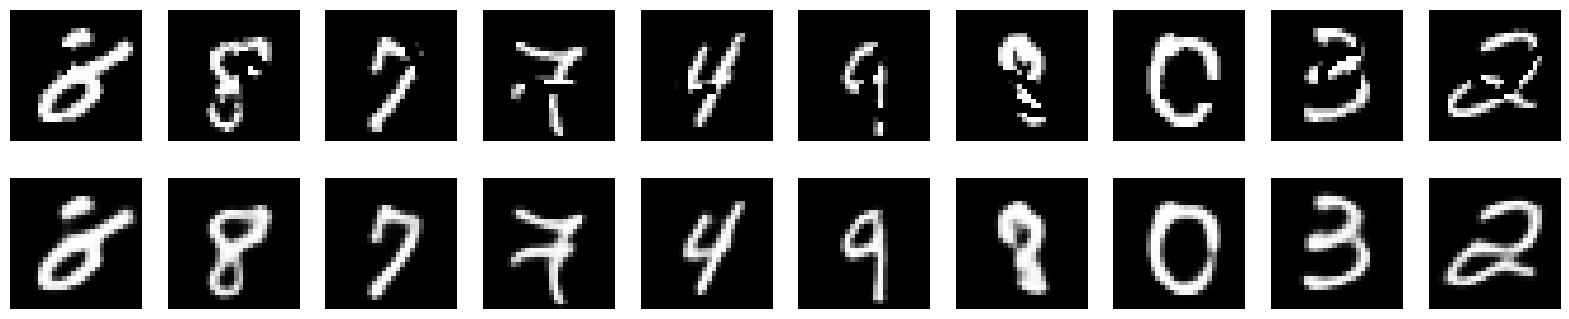

In [16]:
autoencoder.eval()
plt.figure(figsize=(20, 4))
for i in range(10):
    img_in = loaded_images[i].unsqueeze(0).to(device)
    with torch.no_grad():
        img_out = autoencoder(img_in).cpu().squeeze()

    # Vstup
    plt.subplot(2, 10, i + 1)
    plt.imshow(img_in.cpu().squeeze(), cmap='gray')
    plt.axis('off')
    # Výstup
    plt.subplot(2, 10, i + 11)
    plt.imshow(img_out, cmap='gray')
    plt.axis('off')
plt.show()


In [17]:

# 1. Inpainting inference on corrupted digit dataset using fine-tuned repairer model
model_repairer = autoencoder
model_repairer.eval()

# 2. Spracovanie všetkých 2000 obrázkov
fixed_images_list = []

print("Opravujem číslice...")
with torch.no_grad():
    for i in range(len(new_dataset)):
        # Získanie pogumovaného obrázka
        img_rubbered = new_dataset[i][0].unsqueeze(0).to(device)

        # Oprava modelom
        output = model_repairer(img_rubbered)
        fixed_images_list.append(output.cpu())

fixed_digits_tensor = torch.cat(fixed_images_list, dim=0)
torch.save(fixed_digits_tensor, "2000_fixed_digits.pt")

print(f"Hotovo! Súbor 2000_fixed_digits.pt bol vytvorený. Tvar: {fixed_digits_tensor.shape}")


Opravujem číslice...
Hotovo! Súbor 2000_fixed_digits.pt bol vytvorený. Tvar: torch.Size([2000, 1, 28, 28])


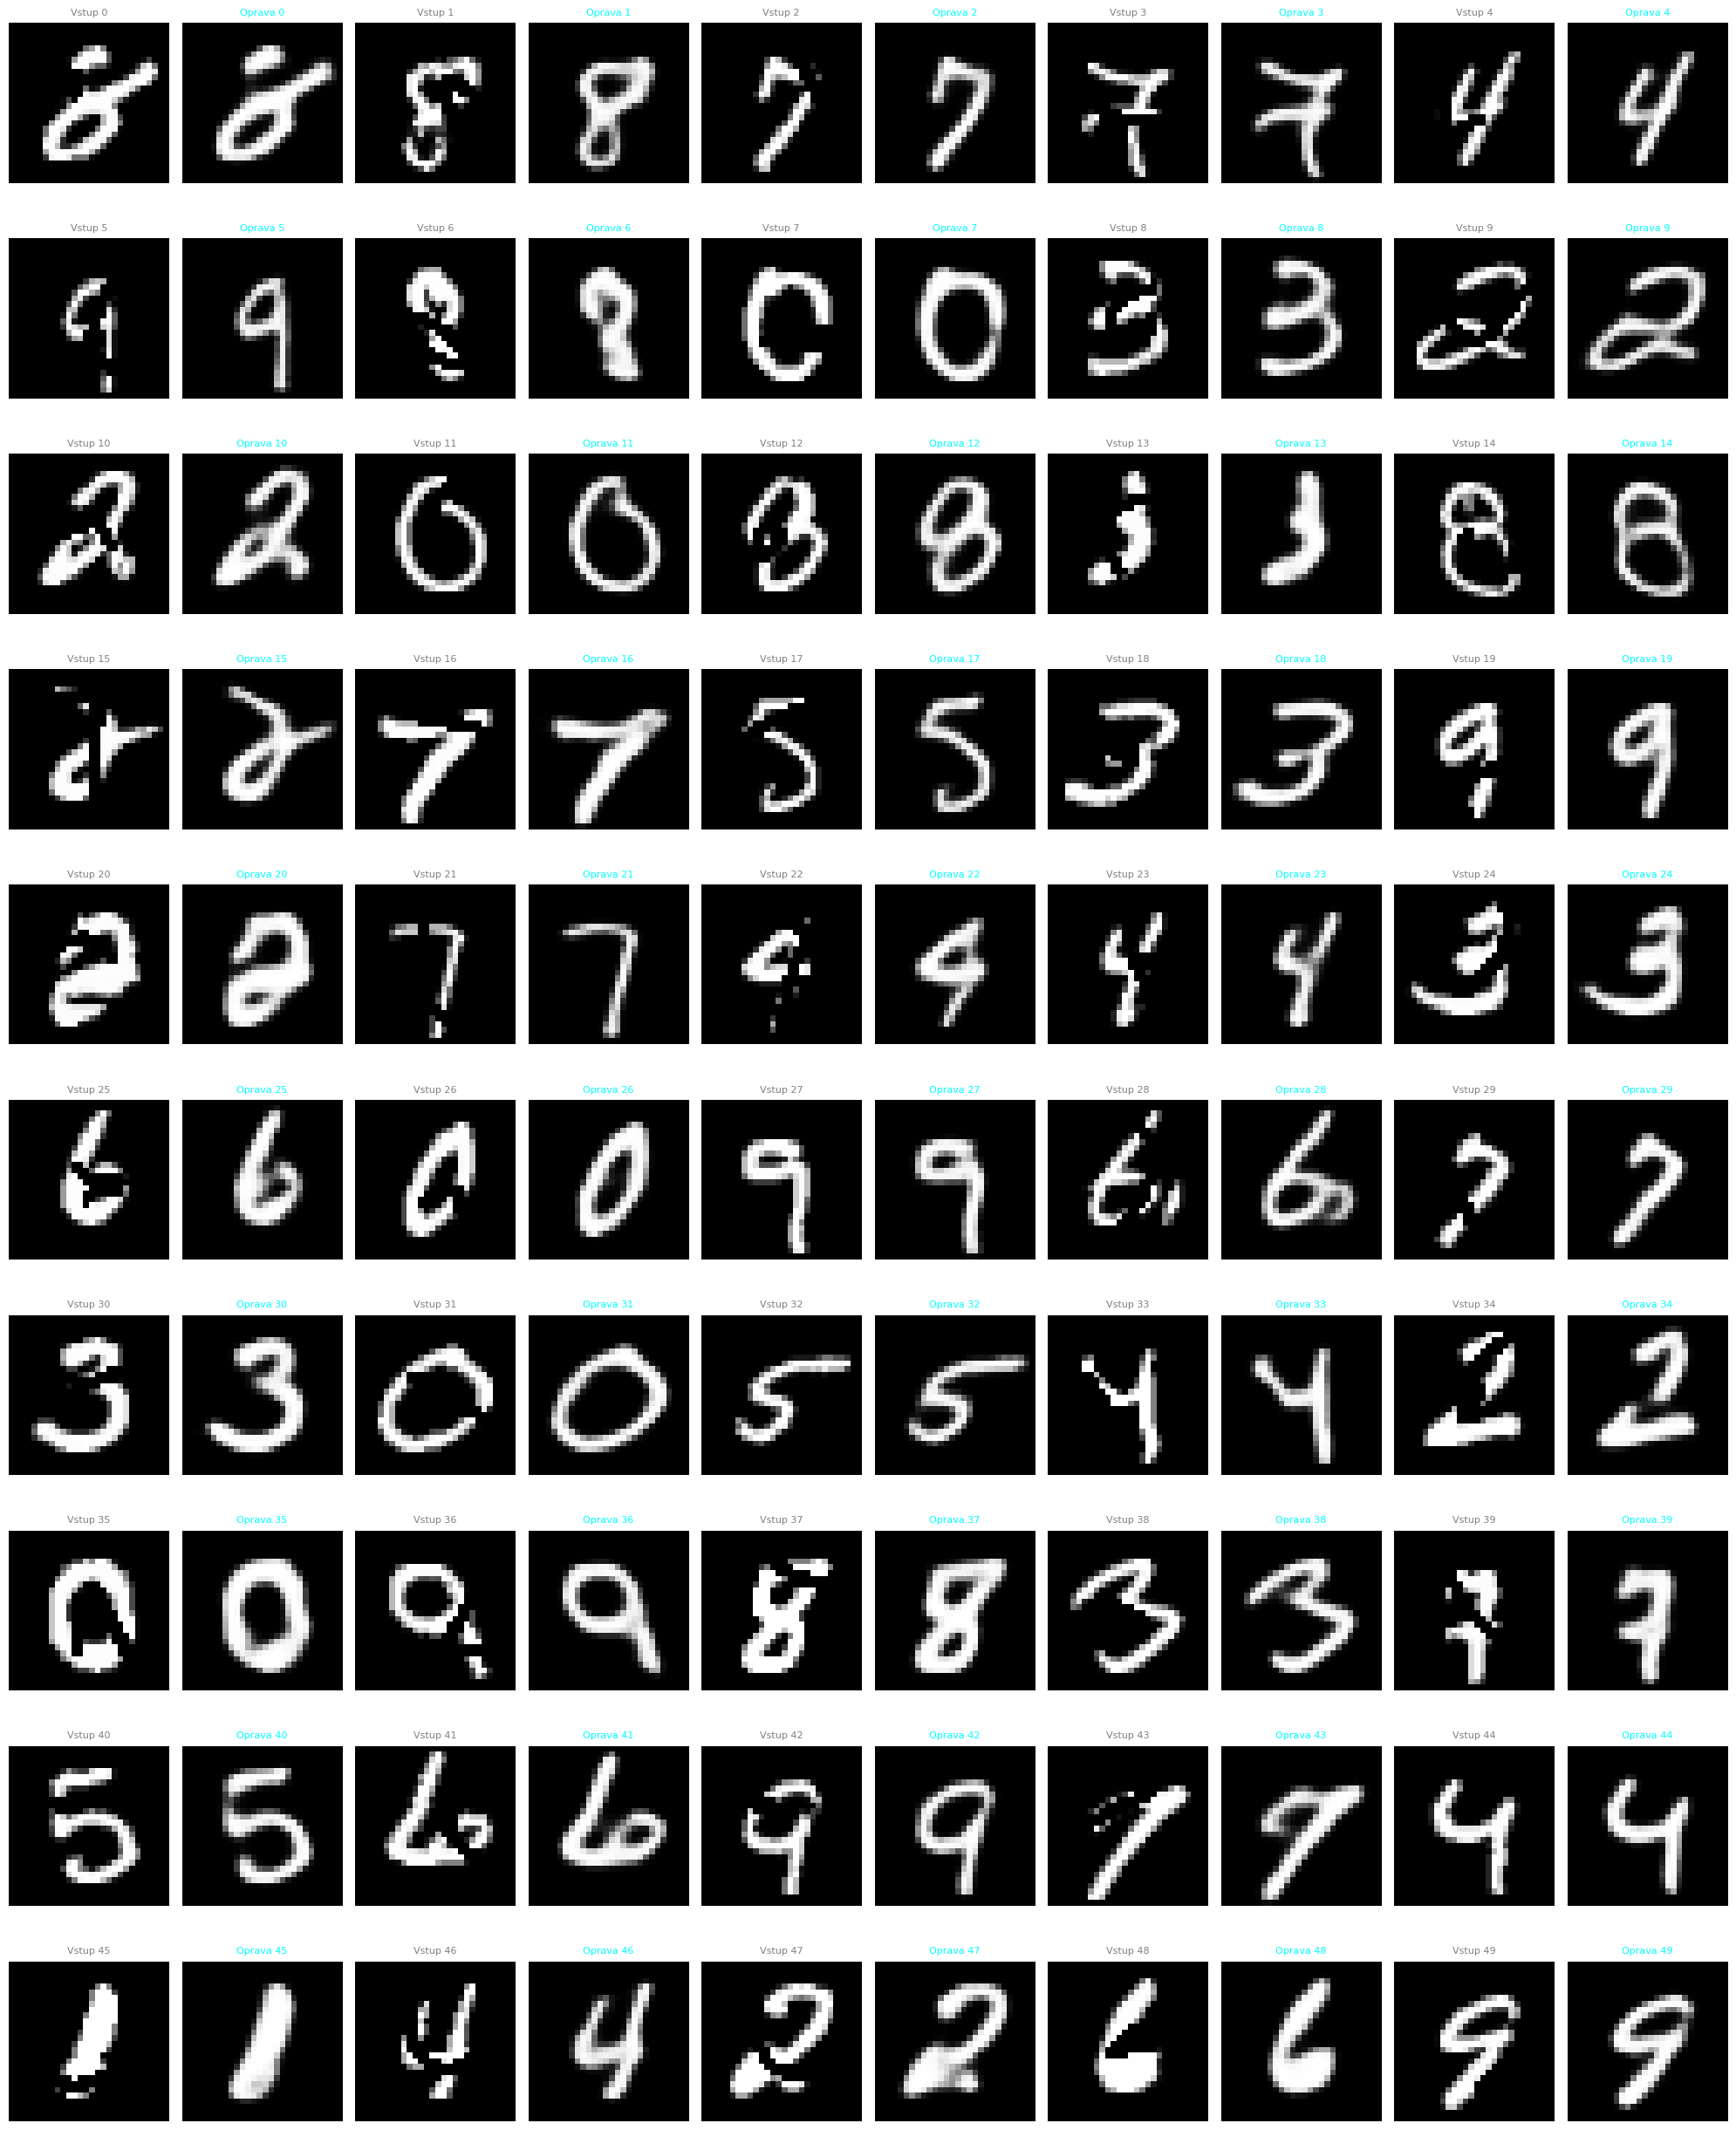

In [19]:
# Validation preview: comparing corrupted inputs with restored outputs


plt.figure(figsize=(20, 25))

model_repairer.eval()

for i in range(50):

    img_rubbered = new_dataset[i][0].unsqueeze(0).to(device)

    with torch.no_grad():
        output = model_repairer(img_rubbered)



    # Kreslenie Vstupu
    plt.subplot(10, 10, (i // 5) * 10 + (i % 5) * 2 + 1)
    plt.imshow(img_rubbered.cpu().squeeze(), cmap='gray', vmin=0, vmax=1)
    plt.title(f"Vstup {i}", fontsize=8, color='gray')
    plt.axis('off')

    # Kreslenie Výstupu
    plt.subplot(10, 10, (i // 5) * 10 + (i % 5) * 2 + 2)
    plt.imshow(output.cpu().squeeze(), cmap='gray', vmin=0, vmax=1)
    plt.title(f"Oprava {i}", fontsize=8, color='cyan')
    plt.axis('off')

plt.tight_layout()
plt.show()


In [ ]:

from google.colab import files

torch.save(autoencoder.state_dict(), "repairer.pth")
print("Model repairer.pth bol úspešne uložený.")

files.download('repairer.pth')
files.download('2000_fixed_digits.pt')
print("Subory uspesne stiahnute")
